# Sensor virtual de % Sílice en concentrado de flotación
**Objetivo:** predecir la impureza de sílice (% SiO2) del concentrado de una planta de flotación de hierro usando variables de proceso, para anticipar el resultado de laboratorio (que demora ~1 hora) y permitir ajustar la operación antes.

**Datos:** planta de flotación real (Brasil, marzo a septiembre de 2017), 737.453 registros y 24 variables.

In [4]:
import pandas as pd

ruta = "/kaggle/input/datasets/edumagalhaes/quality-prediction-in-a-mining-process/MiningProcess_Flotation_Plant_Database.csv"
df = pd.read_csv(ruta, decimal=",", parse_dates=["date"])

print(df.shape)
df.head()

(737453, 24)


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


In [5]:
# ¿Cuántos registros hay por cada hora?
registros_por_hora = df.groupby("date").size()
print(registros_por_hora.value_counts().head())

# ¿Hay saltos en el tiempo?
horas = df["date"].drop_duplicates().sort_values()
print(horas.diff().value_counts().head())


180    4095
174       1
179       1
Name: count, dtype: int64
date
0 days 01:00:00     4095
13 days 07:00:00       1
Name: count, dtype: int64


In [6]:
# 1) ¿Dónde está el hueco?
saltos = horas.diff()
fin_hueco = horas[saltos > pd.Timedelta(hours=1)]
print("Los datos se reanudan en:", fin_hueco.values)

# 2) Quedarnos solo con el período continuo (después del hueco)
df = df[df["date"] >= fin_hueco.iloc[0]].copy()

# 3) Agregar a nivel horario: promedio de cada variable en cada hora
dfh = df.groupby("date").mean().sort_index()
print("Tabla horaria:", dfh.shape)
print("Desde", dfh.index.min(), "hasta", dfh.index.max())


Los datos se reanudan en: ['2017-03-29T12:00:00.000000000']
Tabla horaria: (3948, 23)
Desde 2017-03-29 12:00:00 hasta 2017-09-09 23:00:00


## Limpieza y agregación
- Las variables de proceso se registran cada 20 s (180 por hora), pero el % de sílice se mide en laboratorio una vez por hora. Por eso agrego los datos a nivel horario (promedio).
- Detecté un hueco de 13 días sin datos en marzo de 2017. Para mantener la continuidad temporal, uso solo el período posterior al hueco.


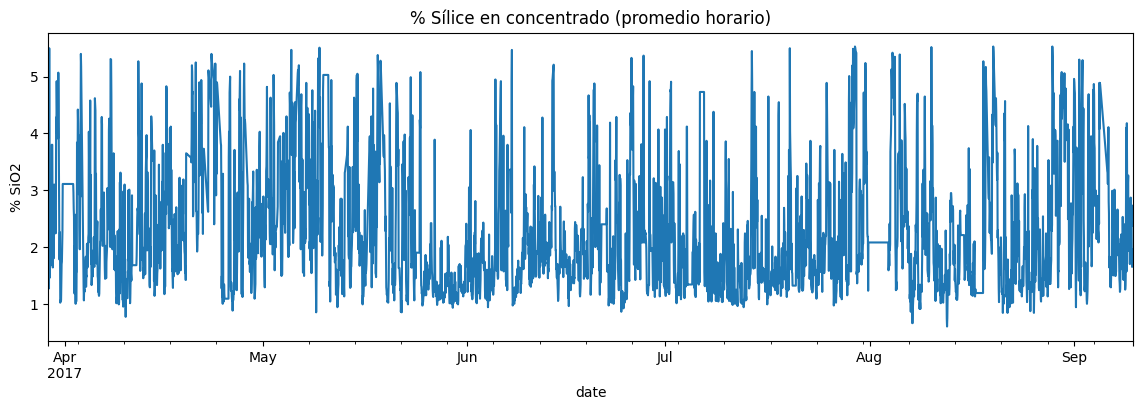

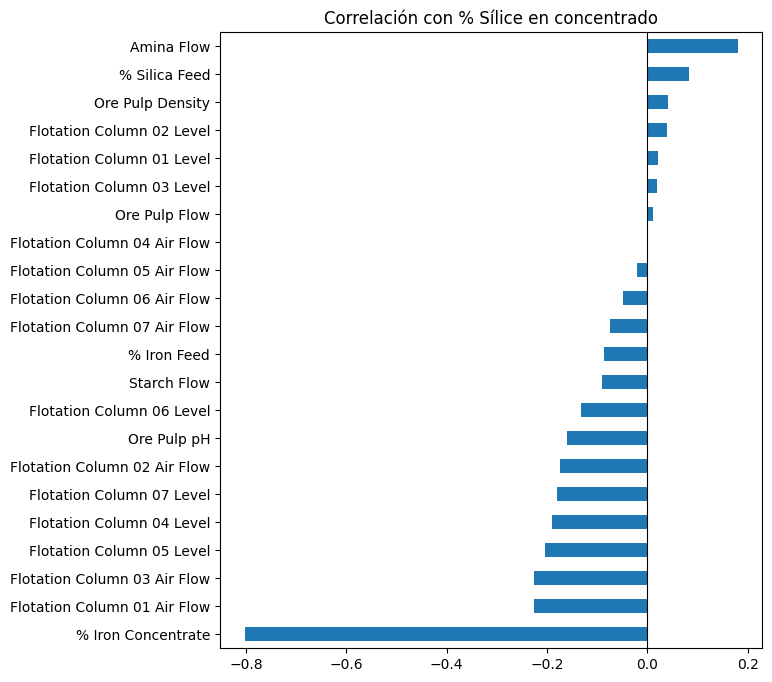

% Iron Concentrate             -0.80
Flotation Column 01 Air Flow   -0.23
Flotation Column 03 Air Flow   -0.23
Flotation Column 05 Level      -0.20
Flotation Column 04 Level      -0.19
Flotation Column 07 Level      -0.18
Flotation Column 02 Air Flow   -0.17
Ore Pulp pH                    -0.16
Flotation Column 06 Level      -0.13
Starch Flow                    -0.09
% Iron Feed                    -0.09
Flotation Column 07 Air Flow   -0.07
Flotation Column 06 Air Flow   -0.05
Flotation Column 05 Air Flow   -0.02
Flotation Column 04 Air Flow    0.00
Ore Pulp Flow                   0.01
Flotation Column 03 Level       0.02
Flotation Column 01 Level       0.02
Flotation Column 02 Level       0.04
Ore Pulp Density                0.04
% Silica Feed                   0.08
Amina Flow                      0.18
Name: % Silica Concentrate, dtype: float64


In [7]:
import matplotlib.pyplot as plt

objetivo = "% Silica Concentrate"

# 1) Evolución de la sílice en el tiempo
dfh[objetivo].plot(figsize=(14,4), title="% Sílice en concentrado (promedio horario)")
plt.ylabel("% SiO2")
plt.show()

# 2) Correlación de cada variable con la sílice
corr = dfh.corr()[objetivo].drop(objetivo).sort_values()
corr.plot(kind="barh", figsize=(7,8), title="Correlación con % Sílice en concentrado")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

print(corr.round(2))


## Análisis exploratorio
- El % de sílice varía entre ~1% y ~5,5% hora a hora: el proceso tiene alta variabilidad.
- **% Iron Concentrate** tiene correlación de -0,80 con la sílice, pero **se excluye como entrada**: proviene del mismo análisis de laboratorio que queremos anticipar (sería *data leakage*).
- Las variables de proceso tienen correlaciones bajas (|r| < 0,25). Las más relevantes son el flujo de aire y el nivel de las columnas de flotación (negativas) y el flujo de amina (positiva, probablemente porque el operador la ajusta en respuesta a la sílice alta).
- Las relaciones débiles e individuales sugieren un comportamiento **no lineal y multivariable**, adecuado para modelos de ML.


In [8]:
# Variables de entrada (sin el objetivo ni el % de hierro, que sería fuga de información)
X_cols_A = [c for c in dfh.columns if c not in [objetivo, "% Iron Concentrate"]]

# Escenario B: además, la última medición de laboratorio conocida (1 y 2 horas antes)
dfh["silica_lag1"] = dfh[objetivo].shift(1)
dfh["silica_lag2"] = dfh[objetivo].shift(2)
dfh = dfh.dropna()
X_cols_B = X_cols_A + ["silica_lag1", "silica_lag2"]

# Separación temporal: 80% primeras horas para entrenar, 20% últimas para probar
corte = int(len(dfh) * 0.8)
train, test = dfh.iloc[:corte], dfh.iloc[corte:]
y_train, y_test = train[objetivo], test[objetivo]

print("Variables escenario A:", len(X_cols_A), "| escenario B:", len(X_cols_B))
print("Entrenamiento:", train.index.min(), "→", train.index.max(), "|", len(train), "horas")
print("Prueba:       ", test.index.min(), "→", test.index.max(), "|", len(test), "horas")


Variables escenario A: 21 | escenario B: 23
Entrenamiento: 2017-03-29 14:00:00 → 2017-08-08 01:00:00 | 3156 horas
Prueba:        2017-08-08 02:00:00 → 2017-09-09 23:00:00 | 790 horas


In [9]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluar(nombre, y_real, y_pred):
    return {"Modelo": nombre,
            "MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
            "R2": r2_score(y_real, y_pred)}

resultados = []

# Líneas base: lo mínimo que un modelo debe superar
resultados.append(evaluar("Base: promedio", y_test, np.full(len(y_test), y_train.mean())))
resultados.append(evaluar("Base: persistencia (valor hora anterior)", y_test, test["silica_lag1"]))

modelos = {
    "Ridge (lineal)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=42),
}

for escenario, cols in [("A", X_cols_A), ("B", X_cols_B)]:
    for nombre, modelo in modelos.items():
        modelo.fit(train[cols], y_train)
        pred = modelo.predict(test[cols])
        resultados.append(evaluar(f"{nombre} [Esc. {escenario}]", y_test, pred))

tabla = pd.DataFrame(resultados).round(3)
tabla


,Modelo,MAE,RMSE,R2
0,Base: promedio,0.945,1.150,-0.000
1,Base: persistencia (valor hora anterior),0.447,0.721,0.606
2,Ridge (lineal) [Esc. A],0.904,1.173,-0.041
3,Random Forest [Esc. A],0.885,1.103,0.079
4,Gradient Boosting [Esc. A],0.881,1.119,0.053
5,Ridge (lineal) [Esc. B],0.478,0.690,0.640
6,Random Forest [Esc. B],0.511,0.703,0.626
7,Gradient Boosting [Esc. B],0.528,0.727,0.601


In [10]:
# 1) Diagnóstico: ¿cuántas horas la sílice queda EXACTAMENTE igual a la hora anterior?
iguales = (dfh[objetivo].diff() == 0).mean()
print(f"Horas con sílice idéntica a la hora anterior: {iguales:.1%}")

# 2) Variables con memoria del proceso: promedio móvil 3 h y cambio respecto a la hora anterior
claves = ["Amina Flow", "Starch Flow", "Ore Pulp pH", "Ore Pulp Density", "Ore Pulp Flow",
          "Flotation Column 01 Air Flow", "Flotation Column 03 Air Flow",
          "Flotation Column 04 Level", "Flotation Column 05 Level", "% Silica Feed"]
for c in claves:
    dfh[c + "_prom3h"] = dfh[c].rolling(3).mean()
    dfh[c + "_cambio"] = dfh[c].diff()
dfh = dfh.dropna()

X_cols_C = X_cols_B + [c + "_prom3h" for c in claves] + [c + "_cambio" for c in claves]

corte = int(len(dfh) * 0.8)
train, test = dfh.iloc[:corte], dfh.iloc[corte:]
y_train, y_test = train[objetivo], test[objetivo]

resultados_C = [evaluar("Base: persistencia", y_test, test["silica_lag1"])]
for nombre, modelo in modelos.items():
    modelo.fit(train[X_cols_C], y_train)
    resultados_C.append(evaluar(f"{nombre} [Esc. C]", y_test, modelo.predict(test[X_cols_C])))

pd.DataFrame(resultados_C).round(3)


Horas con sílice idéntica a la hora anterior: 10.9%


,Modelo,MAE,RMSE,R2
0,Base: persistencia,0.447,0.722,0.606
1,Ridge (lineal) [Esc. C],0.484,0.693,0.638
2,Random Forest [Esc. C],0.504,0.701,0.629
3,Gradient Boosting [Esc. C],0.515,0.713,0.615


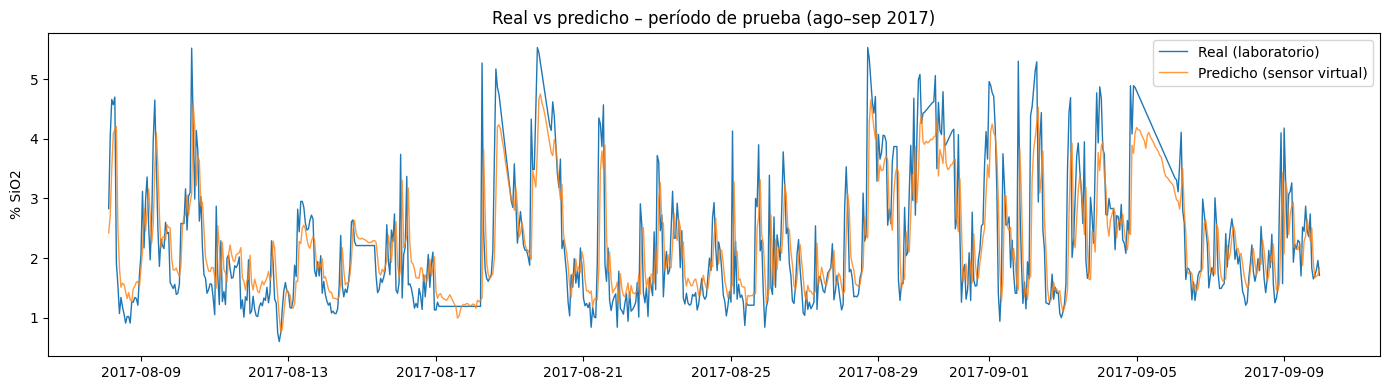

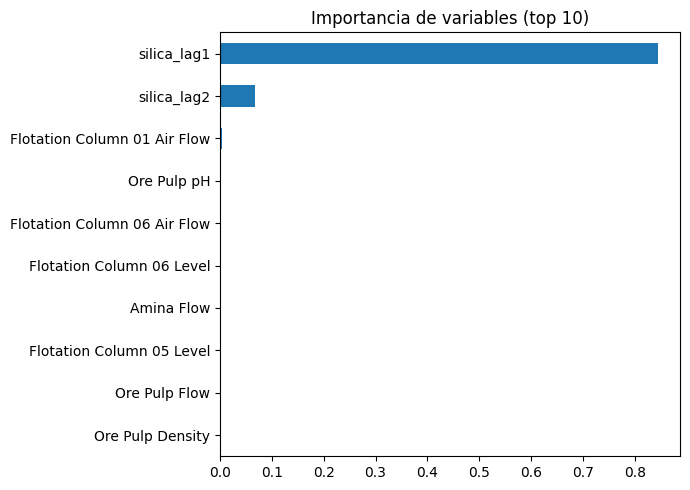

Ore Pulp Density                0.001
Ore Pulp Flow                   0.001
Flotation Column 05 Level       0.001
Amina Flow                      0.001
Flotation Column 06 Level       0.001
Flotation Column 06 Air Flow    0.002
Ore Pulp pH                     0.002
Flotation Column 01 Air Flow    0.004
silica_lag2                     0.068
silica_lag1                     0.845
dtype: float64


In [11]:
from sklearn.inspection import permutation_importance

mejor = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
mejor.fit(train[X_cols_B], y_train)
pred = mejor.predict(test[X_cols_B])

# 1) Real vs predicho en el período de prueba
plt.figure(figsize=(14,4))
plt.plot(test.index, y_test, label="Real (laboratorio)", linewidth=1)
plt.plot(test.index, pred, label="Predicho (sensor virtual)", linewidth=1, alpha=0.8)
plt.ylabel("% SiO2"); plt.title("Real vs predicho – período de prueba (ago–sep 2017)")
plt.legend(); plt.tight_layout()
plt.savefig("real_vs_predicho.png", dpi=150); plt.show()

# 2) ¿Qué variables usa más el modelo?
imp = permutation_importance(mejor, test[X_cols_B], y_test, n_repeats=10, random_state=42)
importancia = pd.Series(imp.importances_mean, index=X_cols_B).sort_values().tail(10)
importancia.plot(kind="barh", figsize=(7,5), title="Importancia de variables (top 10)")
plt.tight_layout(); plt.savefig("importancia_variables.png", dpi=150); plt.show()
print(importancia.round(3))


# Sensor virtual de % Sílice en concentrado de flotación

Modelo de Machine Learning para estimar la impureza de sílice (% SiO2) del concentrado de una planta de flotación de mineral de hierro a partir de variables de proceso. El objetivo es anticipar el resultado de laboratorio, que demora aproximadamente una hora, para ajustar la operación antes.

## Datos
- **Fuente:** [Quality Prediction in a Mining Process (Kaggle)](https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process). Planta real, Brasil, marzo a septiembre de 2017.
- **Tamaño:** 737.453 registros y 24 variables. Las variables de proceso se registran cada 20 s y la calidad una vez por hora (laboratorio).

## Metodología
1. **Limpieza:** se detectó un hueco de 13 días sin datos y se usó solo el período continuo (29-03 al 09-09-2017).
2. **Agregación horaria:** las variables de proceso se promediaron por hora para alinearlas con la frecuencia del laboratorio. Resultado: 3.948 horas.
3. **Control de fuga de información:** se excluyó `% Iron Concentrate` (correlación −0,80), porque proviene del mismo análisis de laboratorio que se quiere anticipar.
4. **Escenarios:**
   - **A:** solo variables de proceso (sensor virtual puro).
   - **B:** variables de proceso más la última medición de laboratorio (1 y 2 h antes).
   - **C:** escenario B más variables con memoria del proceso (promedio de 3 h y tendencia).
5. **Validación temporal:** se entrenó con el 80% inicial (3.156 h) y se evaluó con el 20% final (790 h), sin mezclar al azar.
6. **Modelos:** Ridge, Random Forest y Gradient Boosting, comparados contra dos líneas base: el promedio y la persistencia (el valor de la hora anterior).

## Resultados (período de prueba)

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| Base: promedio | 0,945 | 1,150 | 0,00 |
| Base: persistencia | 0,447 | 0,721 | 0,61 |
| Random Forest, Esc. A (solo proceso) | 0,885 | 1,103 | 0,08 |
| **Ridge, Esc. B (proceso + laboratorio anterior)** | **0,478** | **0,690** | **0,64** |
| Random Forest, Esc. B | 0,511 | 0,703 | 0,63 |
| Ridge, Esc. C (+ memoria de proceso) | 0,484 | 0,693 | 0,64 |

![Real vs predicho](real_vs_predicho.png)
![Importancia de variables](importancia_variables.png)

## Conclusiones
- El mejor modelo (Ridge, escenario B) alcanza **R² = 0,64** y **RMSE = 0,69 % SiO2**. Supera a la persistencia en RMSE (−4%), lo que significa menos errores grandes.
- **Solo con variables de proceso, el R² es menor a 0,1.** Los flujos de aire, el nivel de las columnas, el pH y la amina no bastan para explicar la calidad del concentrado.
- La importancia por permutación confirma que la última medición de laboratorio domina la predicción (0,85), mientras las variables de proceso aportan poco. Agregar memoria de proceso (escenario C) no mejora el resultado.
- La relación positiva entre amina y sílice sugiere un efecto de **control reactivo**: el operador sube la amina cuando la sílice ya está alta, no al revés.

## Recomendaciones para un sensor virtual industrial
- Incorporar variables que expliquen la calidad de la alimentación: mineralogía, liberación y granulometría (P80), o un **analizador en línea**.
- Desplegar el modelo conectado al historiador de planta (por ejemplo, PI), con reentrenamiento periódico y monitoreo de deriva.
- Integrarlo en un **gemelo digital** del circuito de flotación para evaluar estrategias de dosificación de reactivos.

## Herramientas
Python: pandas, NumPy, scikit-learn y matplotlib. Ejecutado en Kaggle Notebooks.

## Autor
Christian Paillacán González, Ingeniero Civil Industrial (UTFSM), especialista en simulación de procesos mineros.
[LinkedIn](https://www.linkedin.com/in/christian-andres-paillacan)